In [2]:
import sys
import os
import time

sys.path.append(os.path.abspath("../src"))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils_cv import baca, tampil, kontras_bercak

os.makedirs("../hasil", exist_ok=True)

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Notebook B4 siap dijalankan.")

OpenCV: 4.11.0
NumPy: 2.2.6
Notebook B4 siap dijalankan.


Ukuran citra: (480, 640)
Tipe data: uint8
KB citra asli: 6.824


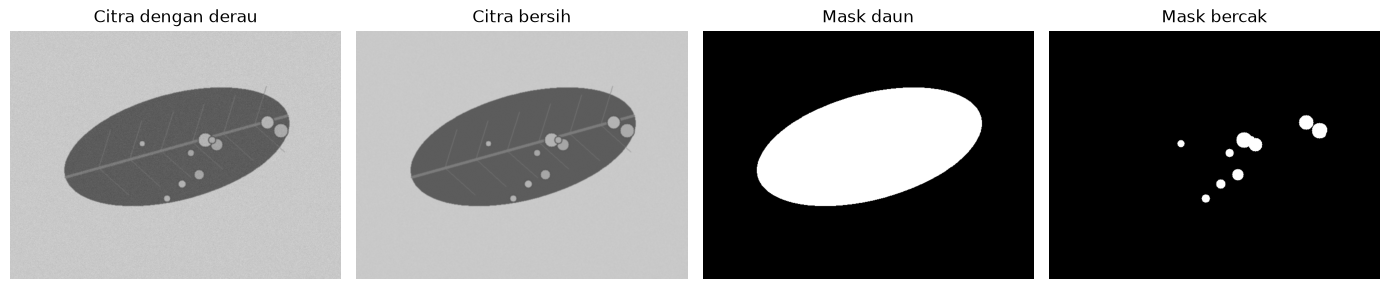

In [3]:
nama = "teh_041.png"

citra_bersih = cv2.cvtColor(
    baca(f"../data/sintetis/bersih/{nama}"),
    cv2.COLOR_BGR2GRAY
)

mask_daun = cv2.imread(
    f"../data/sintetis/mask_daun/{nama}", 0
)

mask_bercak = cv2.imread(
    f"../data/sintetis/mask_bercak/{nama}", 0
)

citra_asli = cv2.cvtColor(
    baca(f"../data/sintetis/citra/{nama}"),
    cv2.COLOR_BGR2GRAY
)

print("Ukuran citra:", citra_bersih.shape)
print("Tipe data:", citra_bersih.dtype)
print("KB citra asli:", round(
    kontras_bercak(citra_asli, mask_daun, mask_bercak), 3
))

tampil(
    [citra_asli, citra_bersih, mask_daun, mask_bercak],
    ["Citra dengan derau", "Citra bersih", "Mask daun", "Mask bercak"],
    ukuran=(14, 4)
)
plt.show()

In [4]:
P = np.array([
    [52, 55, 61, 58],
    [59, 255, 64, 60],
    [62, 60, 0, 57],
    [58, 61, 59, 63]
])

print(P)

[[ 52  55  61  58]
 [ 59 255  64  60]
 [ 62  60   0  57]
 [ 58  61  59  63]]


In [5]:
kernel_rerata = np.ones((3, 3)) / 9

kernel_gaussian = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=float) / 16

hasil_rerata = np.zeros((2, 2))
hasil_gaussian = np.zeros((2, 2))
hasil_median = np.zeros((2, 2))

for y in range(2):
    for x in range(2):
        area = P[y:y+3, x:x+3]

        hasil_rerata[y, x] = np.sum(area * kernel_rerata)
        hasil_gaussian[y, x] = np.sum(area * kernel_gaussian)
        hasil_median[y, x] = np.median(area)

print("Hasil rerata:\n", np.round(hasil_rerata, 2))
print("Hasil Gaussian:\n", np.round(hasil_gaussian, 2))
print("Hasil median:\n", hasil_median.astype(int))

Hasil rerata:
 [[74.22 74.44]
 [75.33 75.44]]
Hasil Gaussian:
 [[104.44  77.38]
 [ 77.25  57.44]]
Hasil median:
 [[60 60]
 [60 60]]


In [6]:
Q = np.array([
    [70, 72, 75],
    [74, 120, 78],
    [73, 76, 79]
])

kernel_tajam = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

hasil_tajam = np.sum(Q * kernel_tajam)
hasil_clipping = np.clip(hasil_tajam, 0, 255)

print("Hasil sebelum clipping:", hasil_tajam)
print("Hasil setelah clipping:", hasil_clipping)

Hasil sebelum clipping: 300
Hasil setelah clipping: 255


In [7]:
baris = np.array([[12, 30, 45, 70]])

zero = np.pad(baris, ((0, 0), (1, 1)), mode="constant")
replicate = np.pad(baris, ((0, 0), (1, 1)), mode="edge")
reflect = np.pad(baris, ((0, 0), (1, 1)), mode="reflect")

print("Zero padding:", zero)
print("Replicate:", replicate)
print("Reflect:", reflect)

print("Rerata piksel pertama:")
print("Zero:", zero[0, 0:3].mean())
print("Replicate:", replicate[0, 0:3].mean())
print("Reflect:", reflect[0, 0:3].mean())

Zero padding: [[ 0 12 30 45 70  0]]
Replicate: [[12 12 30 45 70 70]]
Reflect: [[30 12 30 45 70 45]]
Rerata piksel pertama:
Zero: 14.0
Replicate: 18.0
Reflect: 24.0


In [8]:
def konvolusi(img, k):
    kh, kw = k.shape
    ph, pw = kh // 2, kw // 2

    pad = np.pad(
        img.astype(float),
        ((ph, ph), (pw, pw)),
        mode="edge"
    )

    out = np.zeros(img.shape)

    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            area = pad[y:y+kh, x:x+kw]
            out[y, x] = np.sum(area * k)

    return np.clip(np.round(out), 0, 255).astype(np.uint8)


def konvolusi_sejati(img, k):
    return konvolusi(img, np.flip(k))

In [9]:
kernel_uji = {
    "rerata": np.ones((3, 3)) / 9,

    "asimetris": np.array([
        [1, 0, -1],
        [2, 0, -2],
        [1, 0, -1]
    ], dtype=float)
}

for nama_kernel, kernel in kernel_uji.items():

    t0 = time.perf_counter()
    hasil_manual = konvolusi(citra_bersih, kernel)
    waktu_manual = time.perf_counter() - t0

    t0 = time.perf_counter()
    hasil_cv = cv2.filter2D(
        citra_bersih,
        -1,
        kernel,
        borderType=cv2.BORDER_REPLICATE
    )
    waktu_cv = time.perf_counter() - t0

    hasil_sejati = konvolusi_sejati(citra_bersih, kernel)

    beda_manual = np.abs(
        hasil_manual.astype(int) - hasil_cv.astype(int)
    ).max()

    beda_sejati = np.abs(
        hasil_sejati.astype(int) - hasil_cv.astype(int)
    ).max()

    print(f"\nKernel: {nama_kernel}")
    print("Selisih manual vs filter2D:", beda_manual)
    print("Selisih konvolusi sejati vs filter2D:", beda_sejati)
    print(f"Waktu manual: {waktu_manual:.4f} detik")
    print(f"Waktu OpenCV: {waktu_cv:.5f} detik")


Kernel: rerata
Selisih manual vs filter2D: 0
Selisih konvolusi sejati vs filter2D: 0
Waktu manual: 0.9059 detik
Waktu OpenCV: 0.00809 detik

Kernel: asimetris
Selisih manual vs filter2D: 0
Selisih konvolusi sejati vs filter2D: 255
Waktu manual: 0.9092 detik
Waktu OpenCV: 0.00020 detik


In [10]:
rng = np.random.default_rng(42)

def derau_gauss(img, sd):
    noise = rng.normal(0, sd, img.shape)
    return np.clip(
        img.astype(float) + noise, 0, 255
    ).astype(np.uint8)


def derau_sp(img, p):
    out = img.copy()
    m = rng.random(img.shape)

    out[m < p / 2] = 0
    out[m > 1 - p / 2] = 255

    return out


def ukur_waktu(f, x, ulang=20):
    daftar_waktu = []

    for _ in range(ulang):
        t0 = time.perf_counter()
        f(x)
        daftar_waktu.append(time.perf_counter() - t0)

    return 1000 * np.mean(daftar_waktu)

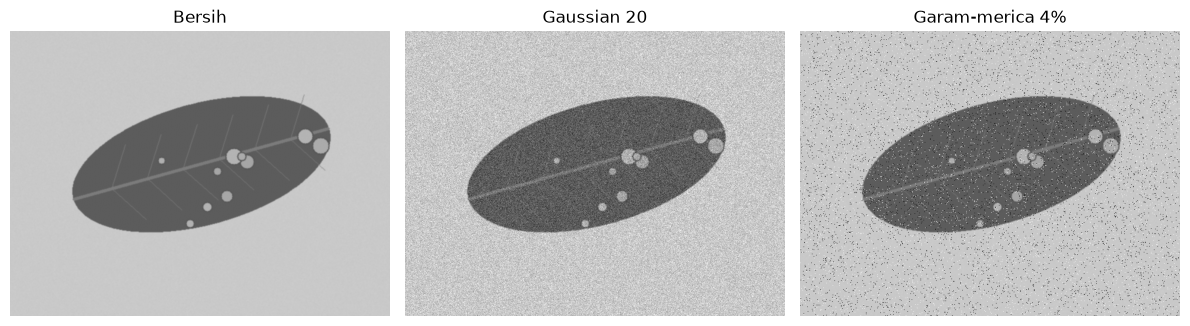

In [11]:
derau = {
    "gauss_10": derau_gauss(citra_bersih, 10),
    "gauss_20": derau_gauss(citra_bersih, 20),
    "gauss_40": derau_gauss(citra_bersih, 40),
    "sp_4%": derau_sp(citra_bersih, 0.04),
    "sp_10%": derau_sp(citra_bersih, 0.10)
}

penapis = {
    "rerata_3": lambda x: cv2.blur(x, (3, 3)),
    "rerata_5": lambda x: cv2.blur(x, (5, 5)),
    "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
    "median_3": lambda x: cv2.medianBlur(x, 3),
    "median_5": lambda x: cv2.medianBlur(x, 5),
    "median_9": lambda x: cv2.medianBlur(x, 9)
}

tampil(
    [citra_bersih, derau["gauss_20"], derau["sp_4%"]],
    ["Bersih", "Gaussian 20", "Garam-merica 4%"],
    ukuran=(12, 4)
)
plt.show()

In [12]:
baris = []

for nama_derau, citra_derau in derau.items():

    baris.append([
        nama_derau,
        "tanpa",
        cv2.PSNR(citra_bersih, citra_derau),
        0.0,
        kontras_bercak(citra_derau, mask_daun, mask_bercak)
    ])

    for nama_penapis, fungsi in penapis.items():

        hasil = fungsi(citra_derau)

        psnr = cv2.PSNR(citra_bersih, hasil)
        waktu = ukur_waktu(fungsi, citra_derau)
        kb = kontras_bercak(hasil, mask_daun, mask_bercak)

        baris.append([
            nama_derau,
            nama_penapis,
            psnr,
            waktu,
            kb
        ])

tabel_penapis = pd.DataFrame(
    baris,
    columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]
).round(2)

display(tabel_penapis)

tabel_penapis.to_csv(
    "../hasil/b4_tabel_penapis.csv",
    index=False
)

,derau,penapis,PSNR_dB,waktu_ms,KB
0,gauss_10,tanpa,28.11,0.00,4.45
1,gauss_10,rerata_3,36.78,0.18,7.01
2,gauss_10,rerata_5,37.15,0.21,6.86
3,gauss_10,gauss_5,37.55,0.07,7.16
4,gauss_10,median_3,35.48,0.22,7.10
5,gauss_10,median_5,38.37,1.35,8.05
6,gauss_10,median_9,38.38,6.79,8.53
7,gauss_20,tanpa,22.12,0.00,2.50
8,gauss_20,rerata_3,31.41,0.17,5.50
9,gauss_20,rerata_5,34.27,0.21,6.17


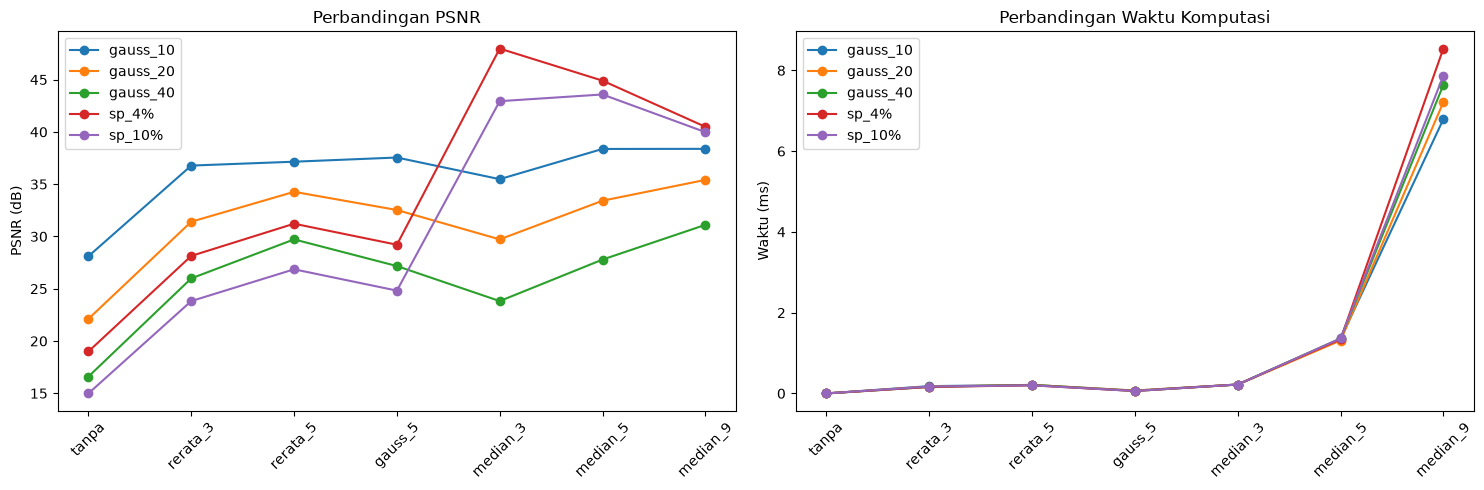

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for nama_derau in tabel_penapis["derau"].unique():

    data = tabel_penapis[
        tabel_penapis["derau"] == nama_derau
    ]

    axes[0].plot(
        data["penapis"],
        data["PSNR_dB"],
        marker="o",
        label=nama_derau
    )

    axes[1].plot(
        data["penapis"],
        data["waktu_ms"],
        marker="o",
        label=nama_derau
    )

axes[0].set_title("Perbandingan PSNR")
axes[0].set_ylabel("PSNR (dB)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend()

axes[1].set_title("Perbandingan Waktu Komputasi")
axes[1].set_ylabel("Waktu (ms)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()

plt.tight_layout()
plt.savefig("../hasil/b4_grafik_psnr_waktu.png", dpi=200)
plt.show()

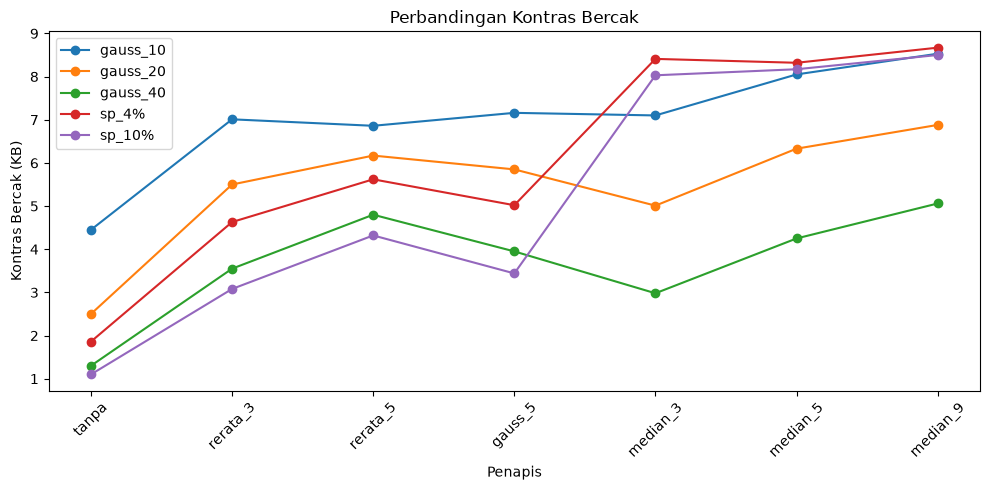

In [14]:
plt.figure(figsize=(10, 5))

for nama_derau in tabel_penapis["derau"].unique():

    data = tabel_penapis[
        tabel_penapis["derau"] == nama_derau
    ]

    plt.plot(
        data["penapis"],
        data["KB"],
        marker="o",
        label=nama_derau
    )

plt.title("Perbandingan Kontras Bercak")
plt.xlabel("Penapis")
plt.ylabel("Kontras Bercak (KB)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.savefig("../hasil/b4_grafik_kb.png", dpi=200)
plt.show()

In [15]:
data_tabel11 = tabel_penapis[
    tabel_penapis["derau"].isin(["gauss_20", "sp_4%"])
]

tabel11 = data_tabel11.pivot(
    index="penapis",
    columns="derau",
    values=["PSNR_dB", "waktu_ms", "KB"]
)

display(tabel11.round(2))

tabel11.to_csv("../hasil/b4_tabel11.csv")

PSNR_dB        waktu_ms             KB      
derau    gauss_20  sp_4% gauss_20 sp_4% gauss_20 sp_4%
penapis                                               
gauss_5     32.53  29.21     0.07  0.06     5.85  5.02
median_3    29.72  47.97     0.22  0.22     5.01  8.41
median_5    33.42  44.90     1.31  1.34     6.33  8.32
median_9    35.41  40.49     7.21  8.54     6.88  8.67
rerata_3    31.41  28.14     0.17  0.16     5.50  4.63
rerata_5    34.27  31.22     0.21  0.20     6.17  5.62
tanpa       22.12  19.00     0.00  0.00     2.50  1.86

In [16]:
def selisih_rerata(kanal, md, mb):
    k = kanal.astype(float)

    sehat = (md > 0) & (mb == 0)
    bercak = mb > 0

    if bercak.sum() == 0 or sehat.sum() == 0:
        return np.nan

    return abs(k[bercak].mean() - k[sehat].mean())


label = pd.read_csv("../data/sintetis/label.csv")

baris_median = []

for nm in label[label["kelas"] == "ringan"]["nama_file"]:

    g = cv2.cvtColor(
        baca(f"../data/sintetis/bersih/{nm}"),
        cv2.COLOR_BGR2GRAY
    )

    md = cv2.imread(
        f"../data/sintetis/mask_daun/{nm}", 0
    )

    mb = cv2.imread(
        f"../data/sintetis/mask_bercak/{nm}", 0
    )

    for k in [1, 3, 5, 9, 15]:

        hasil = g if k == 1 else cv2.medianBlur(g, k)

        di = selisih_rerata(hasil, md, mb)
        kb = kontras_bercak(hasil, md, mb)

        baris_median.append([nm, k, di, kb])

hasil_median = pd.DataFrame(
    baris_median,
    columns=["nama", "kernel", "dI", "KB"]
)

ringkasan_median = hasil_median.groupby("kernel")[
    ["dI", "KB"]
].mean().round(3)

display(ringkasan_median)

hasil_median.to_csv(
    "../hasil/b4_pengaruh_median.csv",
    index=False
)

,dI,KB
kernel,,
1,26.195,4.138
3,26.557,4.257
5,25.221,4.099
9,18.442,3.480
15,5.728,1.613


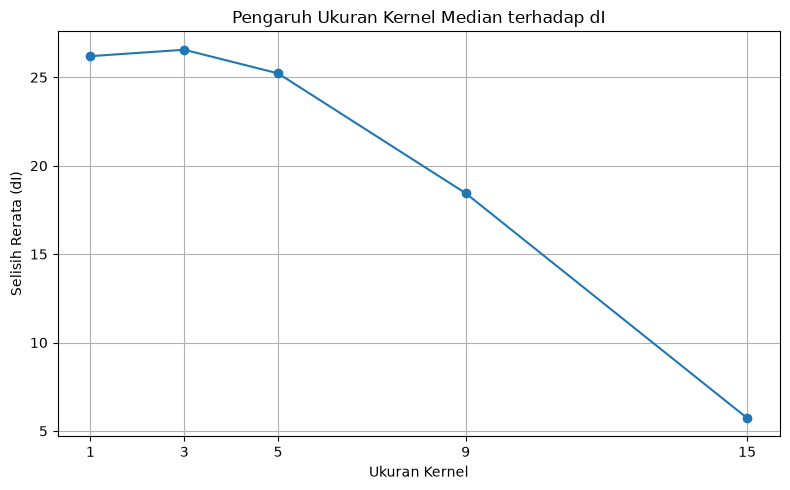

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    ringkasan_median.index,
    ringkasan_median["dI"],
    marker="o"
)

plt.title("Pengaruh Ukuran Kernel Median terhadap dI")
plt.xlabel("Ukuran Kernel")
plt.ylabel("Selisih Rerata (dI)")
plt.xticks([1, 3, 5, 9, 15])
plt.grid(True)
plt.tight_layout()

plt.savefig("../hasil/b4_grafik_di_median.png", dpi=200)
plt.show()

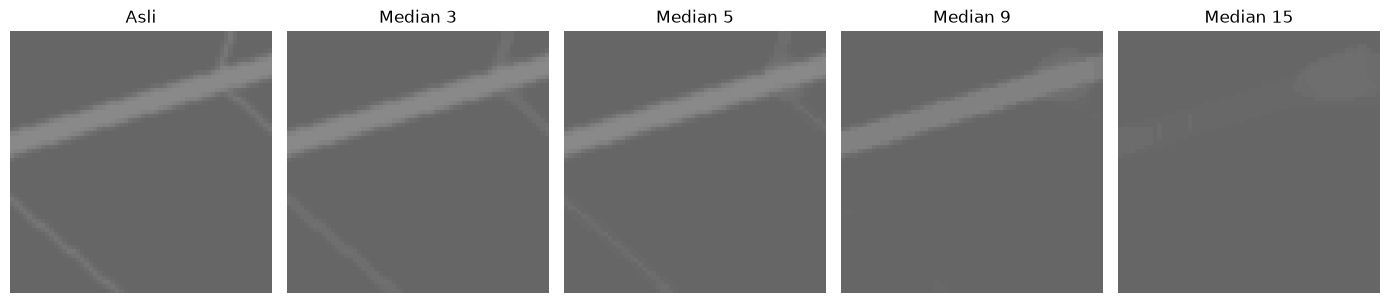

In [18]:
nama_crop = "teh_021.png"

g = cv2.cvtColor(
    baca(f"../data/sintetis/bersih/{nama_crop}"),
    cv2.COLOR_BGR2GRAY
)

# Cari posisi area bercak dari mask
mb = cv2.imread(
    f"../data/sintetis/mask_bercak/{nama_crop}", 0
)

ys, xs = np.where(mb > 0)

y_tengah = int(np.mean(ys))
x_tengah = int(np.mean(xs))

ukuran_crop = 60

y1 = max(0, y_tengah - ukuran_crop // 2)
y2 = min(g.shape[0], y_tengah + ukuran_crop // 2)
x1 = max(0, x_tengah - ukuran_crop // 2)
x2 = min(g.shape[1], x_tengah + ukuran_crop // 2)

crop_asli = g[y1:y2, x1:x2]

hasil_crop = [
    crop_asli,
    cv2.medianBlur(crop_asli, 3),
    cv2.medianBlur(crop_asli, 5),
    cv2.medianBlur(crop_asli, 9),
    cv2.medianBlur(crop_asli, 15)
]

tampil(
    hasil_crop,
    ["Asli", "Median 3", "Median 5", "Median 9", "Median 15"],
    ukuran=(14, 4)
)
plt.show()

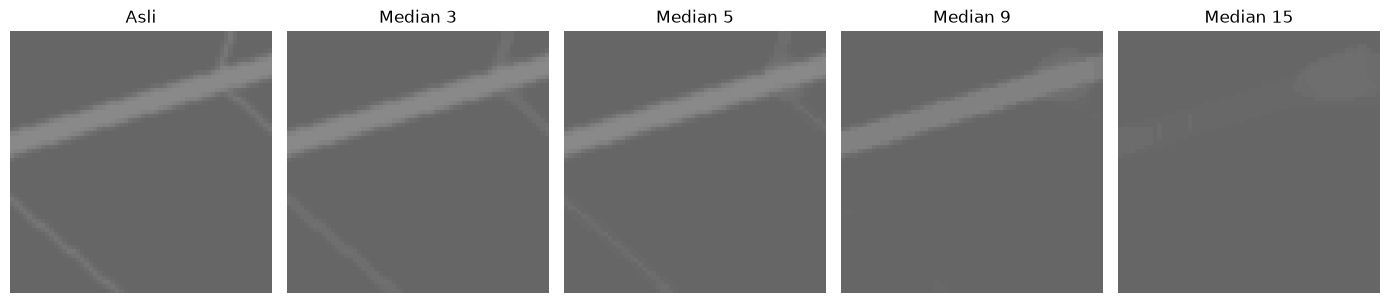

In [19]:
nama_crop = "teh_021.png"

g = cv2.cvtColor(
    baca(f"../data/sintetis/bersih/{nama_crop}"),
    cv2.COLOR_BGR2GRAY
)

# Cari posisi area bercak dari mask
mb = cv2.imread(
    f"../data/sintetis/mask_bercak/{nama_crop}", 0
)

ys, xs = np.where(mb > 0)

y_tengah = int(np.mean(ys))
x_tengah = int(np.mean(xs))

ukuran_crop = 60

y1 = max(0, y_tengah - ukuran_crop // 2)
y2 = min(g.shape[0], y_tengah + ukuran_crop // 2)
x1 = max(0, x_tengah - ukuran_crop // 2)
x2 = min(g.shape[1], x_tengah + ukuran_crop // 2)

crop_asli = g[y1:y2, x1:x2]

hasil_crop = [
    crop_asli,
    cv2.medianBlur(crop_asli, 3),
    cv2.medianBlur(crop_asli, 5),
    cv2.medianBlur(crop_asli, 9),
    cv2.medianBlur(crop_asli, 15)
]

tampil(
    hasil_crop,
    ["Asli", "Median 3", "Median 5", "Median 9", "Median 15"],
    ukuran=(14, 4)
)
plt.show()

In [20]:
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)


noisy = derau["gauss_20"]
latar = mask_daun == 0

for nama, redam in {
    "Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
    "Median": lambda x: cv2.medianBlur(x, 5)
}.items():

    A = redam(unsharp(noisy))
    B = unsharp(redam(noisy))

    print(f"\nPenapis: {nama}")

    print(
        f"Tajam -> redam | "
        f"PSNR={cv2.PSNR(citra_bersih, A):.2f} dB | "
        f"sigma latar={A[latar].std():.2f}"
    )

    print(
        f"Redam -> tajam | "
        f"PSNR={cv2.PSNR(citra_bersih, B):.2f} dB | "
        f"sigma latar={B[latar].std():.2f}"
    )


Penapis: Gaussian
Tajam -> redam | PSNR=30.40 dB | sigma latar=7.80
Redam -> tajam | PSNR=30.20 dB | sigma latar=8.19

Penapis: Median
Tajam -> redam | PSNR=30.14 dB | sigma latar=8.10
Redam -> tajam | PSNR=31.08 dB | sigma latar=7.17


In [21]:
# Ganti pilihan ini berdasarkan hasil eksperimen sebelumnya
nama_penapis_pilihan = "median_3"

fungsi_pilihan = penapis[nama_penapis_pilihan]

nomor_citra = range(1, 57, 5)

baris_normal = []

for nomor in nomor_citra:

    nama = f"teh_{nomor:03d}.png"

    noisy = cv2.cvtColor(
        baca(f"../data/sintetis/citra/{nama}"),
        cv2.COLOR_BGR2GRAY
    )

    bersih = cv2.cvtColor(
        baca(f"../data/sintetis/bersih/{nama}"),
        cv2.COLOR_BGR2GRAY
    )

    hasil = fungsi_pilihan(noisy)

    psnr_sebelum = cv2.PSNR(bersih, noisy)
    psnr_sesudah = cv2.PSNR(bersih, hasil)

    baris_normal.append([
        nama,
        nama_penapis_pilihan,
        psnr_sebelum,
        psnr_sesudah,
        psnr_sesudah - psnr_sebelum
    ])

tabel_normal = pd.DataFrame(
    baris_normal,
    columns=[
        "nama",
        "penapis",
        "PSNR_sebelum",
        "PSNR_sesudah",
        "peningkatan_PSNR"
    ]
).round(2)

display(tabel_normal)

tabel_normal.to_csv(
    "../hasil/b4_psnr_12_citra_normal.csv",
    index=False
)

,nama,penapis,PSNR_sebelum,PSNR_sesudah,peningkatan_PSNR
0,teh_001.png,median_3,28.81,36.22,7.41
1,teh_006.png,median_3,29.13,36.58,7.45
2,teh_011.png,median_3,31.67,38.87,7.21
3,teh_016.png,median_3,29.34,36.72,7.38
4,teh_021.png,median_3,33.39,40.28,6.90
5,teh_026.png,median_3,29.48,36.90,7.42
6,teh_031.png,median_3,35.16,41.95,6.79
7,teh_036.png,median_3,35.15,41.81,6.66
8,teh_041.png,median_3,35.00,41.69,6.69
9,teh_046.png,median_3,34.67,41.37,6.69


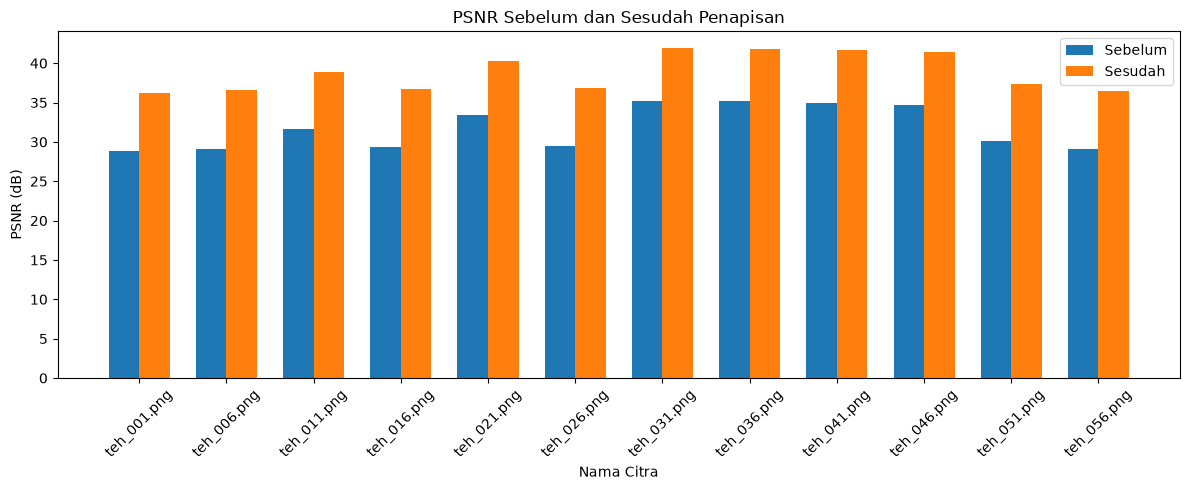

In [22]:
x = np.arange(len(tabel_normal))
lebar = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - lebar / 2,
    tabel_normal["PSNR_sebelum"],
    lebar,
    label="Sebelum"
)

plt.bar(
    x + lebar / 2,
    tabel_normal["PSNR_sesudah"],
    lebar,
    label="Sesudah"
)

plt.xticks(x, tabel_normal["nama"], rotation=45)
plt.xlabel("Nama Citra")
plt.ylabel("PSNR (dB)")
plt.title("PSNR Sebelum dan Sesudah Penapisan")
plt.legend()
plt.tight_layout()

plt.savefig(
    "../hasil/b4_psnr_12_citra_normal.png",
    dpi=200
)

plt.show()